In [ ]:
# Imagen + GT + predicción de Cellpose (axón = verde, mielina = magenta, artefacto = gris)
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import tifffile
from skimage.io import imread

NAME = "sample_0091"                      # una imagen de validación
IMAGE_PATH = Path("data/train_samples") / f"{NAME}.tif"
GT_PATH = Path("data/train_instance_labels") / f"{NAME}.tif"
PRED_DIR = Path("eval_cellpose")          # salida de code/cellpose/evaluate.py (.tif) o cellpose_tem.py (.png)
STEP = 2                                  # se muestra 1 de cada STEP píxeles (más rápido)


def read_mask(path):
    return tifffile.imread(path) if path.suffix.lower() in (".tif", ".tiff") else imread(path)


def overlay(img, y):
    """Codificación del challenge: 0 fondo, 1 artefacto, 2k axón, 2k+1 su mielina."""
    rgb = np.stack([img] * 3, axis=-1).astype(np.float32) / 255
    for mask, color in [((y >= 2) & (y % 2 == 0), (0, 1, 0)),     # axón
                        ((y >= 3) & (y % 2 == 1), (1, 0, 1)),     # mielina
                        (y == 1, (0.5, 0.5, 0.5))]:               # artefacto
        rgb[mask] = 0.55 * rgb[mask] + 0.45 * np.array(color)
    return rgb


def n_fibers(y):
    return len(np.unique(y[y >= 2] // 2))


small = (slice(None, None, STEP), slice(None, None, STEP))
image = tifffile.imread(IMAGE_PATH)[small]   # uint8, escala de grises
gt = tifffile.imread(GT_PATH)[small]         # uint16
pred_paths = [PRED_DIR / f"{NAME}{ext}" for ext in (".tif", ".png") if (PRED_DIR / f"{NAME}{ext}").exists()]
pred = read_mask(pred_paths[0])[small] if pred_paths else None

print("imagen:", image.dtype, "| rango:", image.min(), "-", image.max())
print("GT    :", gt.dtype, "| fibras:", n_fibers(gt), "| tiene artefacto:", bool((gt == 1).any()))
if pred is None:
    print(f"no hay predicción de {NAME} en {PRED_DIR} (¿es una imagen de validación?)")
else:
    print("pred  :", pred.dtype, "| fibras:", n_fibers(pred), "|", pred_paths[0])

panels = [(image, "Imagen", "gray"), (overlay(image, gt), "GT", None)]
if pred is not None:
    panels.append((overlay(image, pred), "Predicción", None))
fig, axes = plt.subplots(1, len(panels), figsize=(6 * len(panels), 6))
for ax, (im, title, cmap) in zip(axes, panels):
    ax.imshow(im, cmap=cmap)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

0 2234, 3456, 21321,
1 34354, 5343, 34534

In [12]:
np.unique(labels)

array([ 0,  1, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24,
       25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41,
       44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 60, 61, 62,
       63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73], dtype=uint16)

100%|██████████| 266/266 [00:34<00:00,  7.60it/s]


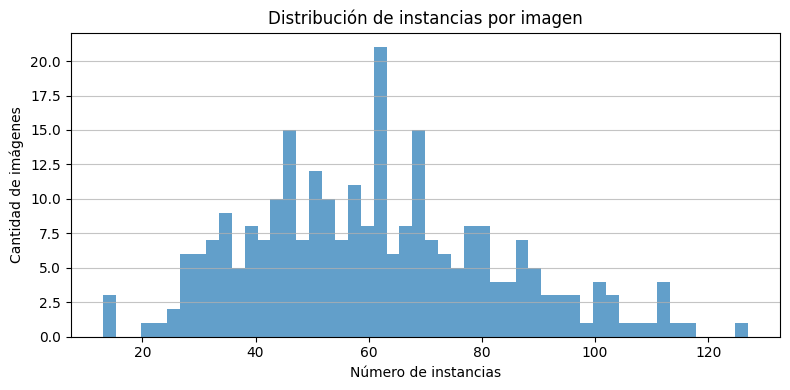

In [ ]:
import os
import numpy as np
from tqdm import tqdm

instancias = []

for filename in tqdm(os.listdir("data/train_instance_labels")):
    if filename.endswith(".tif"):
        path = os.path.join("data/train_instance_labels", filename)
        labels = np.array(Image.open(path))
        ids = np.unique(labels)
        instancias.append(len(ids[ids > 0]))

plt.figure(figsize=(8, 4))
plt.hist(instancias, bins=50, alpha=0.7)
plt.title("Distribución de instancias por imagen")
plt.xlabel("Número de instancias")
plt.ylabel("Cantidad de imágenes")
plt.grid(axis="y", alpha=0.75)
plt.tight_layout()
plt.show()